In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error

import xgboost as xgb

from datetime import date, datetime
import time
import calendar

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
path = '/content/sample_data/'

train = pd.read_csv(path + 'train.csv')
test = pd.read_csv(path + 'test.csv')
sub = pd.read_csv(path + 'sample_submission.csv')

oil = pd.read_csv(path + 'oil.csv')
holiday = pd.read_csv(path + 'holidays_events.csv')
store = pd.read_csv(path + 'stores.csv')
tran = pd.read_csv(path + 'transactions.csv')

In [ ]:
def eda(df):
    print('********************* Top 5 Records *******************')
    print(df.head())
    print('********************* INFO ****************************')
    print(df.info())
    print('********************* Describe ************************')
    print(df.describe())
    print('********************* Colums **************************')
    print(df.columns)
    print('********************* DTYPES **************************')
    print(df.dtypes)
    print('********************* NULL Records ********************')
    print(df.isnull().sum())
    print('********************* NA Records **********************')
    print(df.isna().sum())
    print('********************* Shape ***************************')
    print(df.shape)    
    print('=======================================================')

In [ ]:
eda(train)

In [3]:
#Preproess train and test data with day, month, year
def preprocess_train(df):
    df['date'] = df['date'].map(lambda x: date.fromisoformat(x))
    df['weekday'] = df['date'].map(lambda x: x.weekday())
    df['year'] = df['date'].map(lambda x: x.year)
    df['month'] = df['date'].map(lambda x: x.month)
    df['day'] = df['date'].map(lambda x: x.day)
    df['eomd'] = df['date'].map(lambda x: calendar.monthrange(x.year, x.month)[1])
    df['payday'] = ((df['day'] == df['eomd'])|(df['day'] == 15)).astype(int)
    df.drop(['id', 'eomd'], axis=1, inplace=True)
    return df

train = preprocess_train(train)
test = preprocess_train(test)

In [4]:
#Fill NA value with mean sales of oil in month
def preprocess_oil(oil):
    oil['month'] = oil['date'].map(lambda x: int(x.replace('-', '')[:6]))
    oil['month_avg'] = oil.groupby('month')['dcoilwtico'].transform('mean')
    oil['tmp'] = oil['dcoilwtico'].map(np.isnan)
    oil['month_avg'] = oil['tmp'] * oil['month_avg']
    oil['dcoilwtico'].fillna(0, inplace=True)
    oil['dcoilwtico'] = oil['dcoilwtico'] + oil['month_avg']
    oil = oil.drop(['month', 'month_avg', 'tmp'], axis=1)
    oil['date'] = oil['date'].map(lambda x: date.fromisoformat(x))
    return oil

oil = preprocess_oil(oil)

In [5]:
#Separate holidays into Regional, National, Local and Event
def preprocess_holiday(df):
    df['date'] = df['date'].map(lambda x: date.fromisoformat(x))
    df = df[(df['transferred']==False)&(df['type']!='Work Day')]
    event = df[df['type']=='Event']
    earthquake = event[event['description'].str.startswith('Terremoto Manabi')]
    event = event[event['description'].str.startswith('Terremoto Manabi')==False]
    return df, event, earthquake

holiday, event, earthquake = preprocess_holiday(holiday)

event = event[['date', 'description']]
event.rename({'description': 'event_name'}, axis=1, inplace=True)

earthquake = earthquake[['date', 'description']]
earthquake.rename({'description': 'earthquake'}, axis=1, inplace=True)

h_local = holiday[holiday['locale']=='Local']
h_local = h_local[['date', 'locale_name', 'description']]
h_local = h_local.rename({'locale_name': 'city', 'description': 'local_holiday_name'}, axis=1)

h_regional = holiday[holiday['locale']=='Regional']
h_regional = h_regional[['date', 'locale_name', 'description']]
h_regional = h_regional.rename({'locale_name': 'state', 'description': 'regional_holiday_name'}, axis=1)

h_national = holiday[holiday['locale']=='National']
h_national = h_national[['date', 'description']]
h_national = h_national.rename({'description': 'national_holiday_name'}, axis=1)

In [6]:
#Merge tables
def merge_tables(df):
    df = df.merge(oil, on='date', how='left')
    df = df.merge(store, on='store_nbr', how='left')
    df = df.merge(event, on='date', how='left').fillna('0')
    df = df.merge(earthquake, on='date', how='left').fillna('0')
    df = df.merge(h_local, on=['date', 'city'], how='left').fillna('0')
    df = df.merge(h_regional, on=['date', 'state'], how='left').fillna('0')
    df = df.merge(h_national, on='date', how='left').fillna('0')
    df = df.merge(tran, on=['date', 'store_nbr'], how='left').fillna(0)
    return df

train = merge_tables(train)
test = merge_tables(test)

In [7]:
train['dcoilwtico'] = train['dcoilwtico'].astype(float)
test['dcoilwtico'] = test['dcoilwtico'].astype(float)

In [8]:
#Label Encoding
cat_features = ['family', 'store_nbr', 'city', 'state', 'type', 'cluster',
                'event_name', 'earthquake', 'local_holiday_name', 'regional_holiday_name', 'national_holiday_name']
for col in cat_features:
    le = LabelEncoder()
    train[col] = le.fit_transform(train[col])
    test[col] = le.transform(test[col])

In [9]:
def preprocess_dataset(df, train_date: list, valid_date: list):
    df['is_train'] = df['date'].map(lambda x: x in train_date)
    df['is_valid'] = df['date'].map(lambda x: x in valid_date)
    return df

train_date = train['date'].unique()[-227:-31].tolist()
valid_date = train['date'].unique()[-31:].tolist()
train = preprocess_dataset(train, train_date, valid_date)

In [10]:
print('train date from {} to {}'.format(min(train_date), max(train_date)))
print('valid date from {} to {}'.format(min(valid_date), max(valid_date)))

train date from 2017-01-01 to 2017-07-15
valid date from 2017-07-16 to 2017-08-15


In [19]:
#Set X and Y
#y = np.log(train['sales'] + 1)
y=train['sales']
X_train = train.drop(['date', 'sales', 'year'], axis=1)
X_test = test.drop(['date', 'year'], axis=1)

In [12]:
#XGB Parameters
xgb_params = {
    'tree_method': 'gpu_hist', 
    'gpu_id': 0,
    'predictor': 'gpu_predictor', 
    'verbosity': 2,
    'objective': 'reg:squarederror', 
    'eval_metric': 'rmse', 
    'random_state': 2021,
    'learning_rate': 0.009948916127719946,
    'subsample': 0.9963593946651406,
    'colsample_bytree': 0.8056779523100791,
    'reg_alpha': 10.0,
    'reg_lambda': 0.1801543144548864,
    'min_child_weight': 47,
}

In [13]:
def basic_xgboost(X_train, y, xgb_params, X_test):
    start = time.time()    
    # extract train and valid dataset
    trn_idx = X_train[X_train['is_train']==True].index.tolist()
    val_idx = X_train[X_train['is_valid']==True].index.tolist()

    X_tr = X_train.loc[trn_idx, :].drop(['is_train', 'is_valid'], axis=1)
    X_val = X_train.loc[val_idx, :].drop(['is_train', 'is_valid'], axis=1)
    y_tr = y[trn_idx]
    y_val = y[val_idx]
    
    xgb_train = xgb.DMatrix(X_tr, label=y_tr)
    xgb_valid = xgb.DMatrix(X_val, label=y_val)
    evallist = [(xgb_train, 'train'), (xgb_valid, 'eval')]
    evals_result = dict()
    
    model = xgb.train(params=xgb_params, dtrain=xgb_train, evals=evallist, evals_result=evals_result,
                      verbose_eval=50, num_boost_round=1000, early_stopping_rounds=10)
    
    
    
    xgb_oof = np.zeros(y_val.shape[0])
    #xgb_oof = model.predict(xgb_valid, iteration_range=(0, model.best_iteration))
    xgb_oof = model.predict(xgb_valid)
    
    xgb_test = xgb.DMatrix(X_test)
    #xgb_pred = pd.Series(model.predict(xgb_test, iteration_range=(0, model.best_iteration)), name='xgb_pred')
    xgb_pred = pd.Series(model.predict(xgb_test),
                         name='xgb_pred')
    
    elapsed = time.time() - start
    error_value = mean_squared_error(y_val, xgb_oof, squared=False)
    print(f"xgb rmse: {error_value:.6f}, elapsed time: {elapsed:.2f}sec\n")

    return xgb_oof, model, evals_result, xgb_pred, y_val, X_val

In [12]:
from lightgbm import LGBMRegressor

In [ ]:
trn_idx = X_train[X_train['is_train']==True].index.tolist()
val_idx = X_train[X_train['is_valid']==True].index.tolist()

X_tr = X_train.loc[trn_idx, :].drop(['is_train', 'is_valid'], axis=1)
X_val = X_train.loc[val_idx, :].drop(['is_train', 'is_valid'], axis=1)
y_tr = y[trn_idx]
y_val = y[val_idx]

In [30]:
#Parameters for LightGBM
model=LGBMRegressor(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=32,
        colsample_bytree=0.9497036,
        subsample=0.8715623,
        max_depth=8,
        reg_alpha=0.04,
        reg_lambda=0.073,
        min_split_gain=0.0222415,
        min_child_weight=40)

In [32]:
model.fit(X_tr, y_tr)

LGBMRegressor(colsample_bytree=0.9497036, learning_rate=0.03, max_depth=8,
              min_child_weight=40, min_split_gain=0.0222415, n_estimators=200,
              num_leaves=32, reg_alpha=0.04, reg_lambda=0.073,
              subsample=0.8715623)

In [33]:
y_pred = model.predict(X_val)

In [36]:
error_value = mean_squared_error(y_val, y_pred, squared=False)
err=

338.56157214148465

In [ ]:
df_error = pd.DataFrame()

In [ ]:
#y_oof = df_error[(df_error['store_nbr']==1)&(df_error['family']==12)]['oof'].tolist()
#y_val = df_error[(df_error['store_nbr']==1)&(df_error['family']==12)]['y_valid'].tolist()
sns.lineplot(x=range(len(y)), y=y)
sns.lineplot(x=range(len(y)), y=y_pred)

In [14]:
%%time
oof, model, evals_result, pred, y_val, X_val = basic_xgboost(X_train, y, xgb_params, X_test)

[0]	train-rmse:3.95893	eval-rmse:3.98298
Multiple eval metrics have been passed: 'eval-rmse' will be used for early stopping.

Will train until eval-rmse hasn't improved in 10 rounds.
[50]	train-rmse:2.55815	eval-rmse:2.5865
[100]	train-rmse:1.7506	eval-rmse:1.77499
[150]	train-rmse:1.28831	eval-rmse:1.30784
[200]	train-rmse:1.03909	eval-rmse:1.05427
[250]	train-rmse:0.899784	eval-rmse:0.905984
[300]	train-rmse:0.817948	eval-rmse:0.821183
[350]	train-rmse:0.767849	eval-rmse:0.772461
[400]	train-rmse:0.735199	eval-rmse:0.739032
[450]	train-rmse:0.710338	eval-rmse:0.719664
[500]	train-rmse:0.687147	eval-rmse:0.700517
[550]	train-rmse:0.670005	eval-rmse:0.687411
[600]	train-rmse:0.657434	eval-rmse:0.677263
[650]	train-rmse:0.647045	eval-rmse:0.669109
[700]	train-rmse:0.63746	eval-rmse:0.660193
[750]	train-rmse:0.627868	eval-rmse:0.650612
[800]	train-rmse:0.618588	eval-rmse:0.639553
[850]	train-rmse:0.60916	eval-rmse:0.627407
[900]	train-rmse:0.60213	eval-rmse:0.619376
[950]	train-rmse:0.5

In [16]:
df_error = X_val[['store_nbr', 'family']].copy()
df_error.reset_index(drop=True, inplace=True)
df_error['oof'] = pd.Series(oof)
df_error['y_valid'] = y_val.reset_index(drop=True).copy()

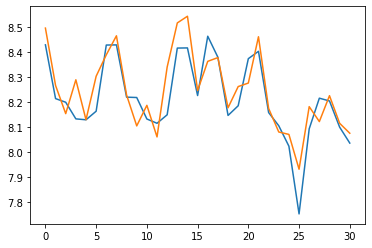

In [17]:
# good
y_oof = df_error[(df_error['store_nbr']==1)&(df_error['family']==12)]['oof'].tolist()
y_val = df_error[(df_error['store_nbr']==1)&(df_error['family']==12)]['y_valid'].tolist()
sns.lineplot(x=range(len(y_oof)), y=y_oof)
sns.lineplot(x=range(len(y_oof)), y=y_val)

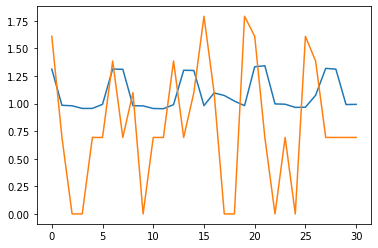

In [18]:
# need to improve
y_oof = df_error[(df_error['store_nbr']==1)&(df_error['family']==14)]['oof'].tolist()
y_val = df_error[(df_error['store_nbr']==1)&(df_error['family']==14)]['y_valid'].tolist()
sns.lineplot(x=range(len(y_oof)), y=y_oof)
sns.lineplot(x=range(len(y_oof)), y=y_val)